# LCL + EN linkage: the synthetic EV dataset (`LCL_EN_join_v2`)

No GB dataset records both a household's whole-meter load and whether it charges an EV at home.
The labelled set is therefore built by **superposition**: 21 days of a real Electric Nation (EN)
home charger's load are added, half-hour by half-hour, to 21 days of a real Low Carbon London (LCL)
household's load.

The dataset is built by `create_ev_dataset_v2.py`, which section 0 runs if its outputs are
missing. Its rules are set out below. This notebook first shows why the segment is 21 days (Table EV_J_T1), then reads the
build's outputs and produces two more tables and two figures.

**The join rules:**
- **Segments.** 21 contiguous days (3 whole weeks) of one charger in one trial regime: T1 control
  (unmanaged charging during Trial 1), T1 demand management, T2 priority-charging app or T3
  time-of-use tariff. The unmanaged (no group) regime is excluded (section 2). One segment per
  charger per regime. A segment must contain at least one charging day.
- **Hosts.** Each segment goes on a different, randomly chosen arm-N household (standard tariff),
  with no heating or dwelling restriction.
- **Placement.** A random date in the host's record (23 Nov 2011 – 27 Feb 2014), starting on the
  same weekday as the segment, so every EV day lands on its own weekday. There is no month
  matching.
- **Clock.** LCL is GMT. Each EV half-hour is shifted by the difference in UK clock offset between
  its source date and its host date (0 or ±1 hour), so charging keeps its local clock time.
- **Negatives.** 21-day windows of other arm-N households (donors), drawn the same way positives
  are placed. Only the negatives the experiments use are built: 3,000 for training and 9 per test
  positive, so the test set is exactly 10% positive.
- **Split.** By charger and by household, before pairing: 70% of chargers train, 30% test, and
  every household has exactly one role.

## 0. Build the dataset

This cell runs `create_ev_dataset_v2.py`, which writes `LCL_EN_join_v2/`. It builds only when the outputs are
missing, so rerunning the notebook does not rebuild the EV dataset. Set `REBUILD = True` to build it again.

In [1]:
import subprocess
import sys
from pathlib import Path

REBUILD = False
SCRIPT = Path.cwd() / "create_ev_dataset_v2.py"
BUILD_DIR = Path.cwd() / "LCL_EN_join_v2"
OUTPUTS = [BUILD_DIR / "join_manifest.json"]

if REBUILD or not all(p.exists() for p in OUTPUTS):
    # Run the build in its own process and show its log here as it runs.
    proc = subprocess.Popen([sys.executable, "-u", str(SCRIPT)], cwd=SCRIPT.parent,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        # Paths relative to the repository root, so the log shows no local folders.
        print(line.replace(str(SCRIPT.parent) + "/", "").replace(str(SCRIPT.parent), "."), end="")
    if proc.wait() != 0:
        raise RuntimeError(f"{SCRIPT.name} failed (exit code {proc.returncode})")
else:
    print(f"{BUILD_DIR.name} already built; set REBUILD = True to build it again")

LCL_EN_join_v2: 21-day single-regime EV segments on arm-N hosts

STEP 1: EN segments (21 contiguous GMT days, one regime, at least one charging day)
                          able_to_supply  positives_with_charging
regime                                                           
T1 control                            32                       28
T1 demand management                 463                      459
T2 priority-charging app             489                      473
T3 time-of-use tariff                451                      418
  1,378 positive segments from 535 chargers (57 charger-regimes never charge in any 21-day window)

STEP 2: LCL arm-N households and valid windows (21 consecutive complete days)
  4,157 households pass the quality filters; 4,157 have a valid window; 120,648 non-overlapping windows

STEP 3: Split by charger and by household (before pairing)
  chargers: 375 train / 160 test | positive segments 984 / 394
  households: 2258 train side / 1899 test side | d

## 1. Setup

In [2]:
from pathlib import Path
import json
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
CACHE_DIR = NB_DIR / "cache"
FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(exist_ok=True)

V2 = NB_DIR / "LCL_EN_join_v2"   # created by create_ev_dataset_v2.py
assert (V2 / "join_manifest.json").exists(), f"build output missing: {V2}"
HH30 = V2 / "ev_dataset_hh30.parquet"
DAILY = V2 / "ev_dataset.parquet"

REGIMES = ["T1 control", "T1 demand management", "T2 priority-charging app",
           "T3 time-of-use tariff"]
REGIME_SHORT = {"Unmanaged": "Unmanaged", "T1 control": "T1 control", "T1 demand management": "T1",
                "T2 priority-charging app": "T2", "T3 time-of-use tariff": "T3"}
SPLITS = {"train": "Training", "test": "Test"}
SEGMENT_DAYS = 21
COMPLETE_DAY_SLOTS = 46
EVENING = (33, 44)                                     # 16:00-22:00, hh_index of period start
OVERNIGHT = tuple(range(45, 49)) + tuple(range(1, 15))  # 22:00-07:00
DAY_LABELS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
HEATMAP_VMAX = 0.65      # shared with Figures LCL6 and EoH4

In [3]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
WEEKDAY_COLOR, WEEKEND_COLOR = CAT["violet"], CAT["aqua"]   # as in notebook 03

SEQ_BLUE_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})

COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}


def hhmm_axis(ax, step_hours=3):
    # Label a 48-slot time-of-day x-axis; slot i spans [i, i+1) (period start).
    ticks = list(range(0, 49, step_hours * 2))
    ax.set_xticks(ticks)
    ax.set_xticklabels(["24:00" if t == 48 else f"{t // 2:02d}:{'00' if t % 2 == 0 else '30'}"
                        for t in ticks])


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df

In [4]:
manifest = json.load(open(V2 / "join_manifest.json"))
meta = pd.read_parquet(V2 / "ev_metadata.parquet")
pos, neg = meta[meta.label == 1], meta[meta.label == 0]
print(f"{manifest['segments']:,} segments: {manifest['positives']:,} positive, "
      f"{manifest['negatives']:,} negative; gates " + ", ".join(
          f"{g} {'PASS' if v else 'FAIL'}" for g, v in manifest["gates"].items()))

7,924 segments: 1,378 positive, 6,546 negative; gates 1_metadata_audit PASS, 2_host_audit PASS, 3_weekday_alignment PASS, 4_integrity PASS, 5_energy PASS, 6_test_prevalence PASS


## 2. Table EV_J_T1 - Choosing the segment length

A segment must stay within one trial regime, so its length is limited by how long chargers stay in
one regime. The tables below are computed from the Electric Nation charger-day record (GMT dates,
notebook 03) for every whole-week length from 7 to 56 days. Unmanaged (no group) is shown for
comparison but is **not used in the join**: 84% of its days come before a charger joins any trial
group, and its windows are empty about four times as often as the other regimes'.

- **(a) Positive segments:** one per charger per regime, from windows that contain at least one
  charging day (the rule the join uses).
- **(b) Windows with no charging:** the share of all windows of that length, in each regime, with
  no charging day. Median charging days and reliability are over the four linkage regimes.
  Reliability is the correlation between a window's weekday-minus-weekend charging-day rate and the
  same charger's rate over its whole single-regime run.

**21 days** is the longest length that keeps T1 control, the only regime with unmanaged charging by
drivers already in the trial, at a usable size (28 segments; 8 at 28 days and none from 49 days).

In [5]:
LENGTHS = [7, 14, 21, 28, 35, 42, 49, 56]
ALL_REGIMES = ["Unmanaged"] + REGIMES
con = duckdb.connect()
con.execute("SET preserve_insertion_order=false")
con.execute(f"""
    CREATE TABLE cd AS
    SELECT provider || ':' || charger_id AS charger, CAST(date AS DATE) AS d, phase AS regime,
           coalesce(charged, false)::INT AS c, dayofweek(CAST(date AS DATE)) IN (0, 6) AS we
    FROM '{CACHE_DIR}/en_charger_day.parquet' WHERE phase IN {tuple(ALL_REGIMES)}""")
con.execute("""CREATE TABLE g AS SELECT *, (d - DATE '2016-01-01')
               - row_number() OVER (PARTITION BY charger, regime ORDER BY d) AS run FROM cd""")
con.execute("""CREATE TABLE runs AS SELECT charger, regime, run,
               avg(c) FILTER (WHERE NOT we) - avg(c) FILTER (WHERE we) AS run_contrast
               FROM g GROUP BY 1, 2, 3""")

supply_rows, empty_rows = [], []
for L in LENGTHS:
    w = con.execute(f"""
        WITH w AS (
            SELECT charger, regime, run,
                   sum(c) OVER win AS n_c, count(*) OVER win AS n_d,
                   sum(c * (NOT we)::INT) OVER win AS wd_c, sum(we::INT) OVER win AS we_n,
                   sum(c * we::INT) OVER win AS we_c
            FROM g
            WINDOW win AS (PARTITION BY charger, regime, run ORDER BY d
                           ROWS BETWEEN CURRENT ROW AND {L - 1} FOLLOWING))
        SELECT w.*, r.run_contrast FROM w JOIN runs r USING (charger, regime, run)
        WHERE n_d = {L}""").df()
    w["contrast"] = w.wd_c / (L - w.we_n) - w.we_c / w.we_n
    pos_by = w[w.n_c > 0].groupby("regime").charger.nunique()
    empty_by = w.groupby("regime").n_c.apply(lambda x: 100 * (x == 0).mean())
    link = w[w.regime.isin(REGIMES)]
    supply_rows.append({"Length (days)": L,
                        **{REGIME_SHORT[r]: int(pos_by.get(r, 0)) for r in ALL_REGIMES},
                        "Linkage total (excl. unmanaged)": int(pos_by.reindex(REGIMES).fillna(0).sum()),
                        "Chargers (linkage regimes)": int(link[link.n_c > 0].charger.nunique())})
    empty_rows.append({"Length (days)": L,
                       **{REGIME_SHORT[r]: (f"{empty_by[r]:.1f}%" if r in empty_by.index else "–")
                          for r in ALL_REGIMES},
                       "Median charging days (linkage)": f"{link.n_c.median():.0f}",
                       "Weekday-vs-weekend reliability": f"{link[['contrast', 'run_contrast']].corr().iloc[0, 1]:.2f}"})
con.close()

t_j3a = pd.DataFrame(supply_rows).set_index("Length (days)")
t_j3a.columns.name = "EV_J_T1a  Positive segments (one per charger and regime, window with charging)"
t_j3b = pd.DataFrame(empty_rows).set_index("Length (days)")
t_j3b.columns.name = "EV_J_T1b  Windows with no charging, by regime"
savetable(t_j3a, "EV_J_T1a_segment_length_supply")
savetable(t_j3b, "EV_J_T1b_segment_length_empty_windows")
display(t_j3a)
display(t_j3b)

saved -> tables/EV_J_T1a_segment_length_supply.csv
saved -> tables/EV_J_T1b_segment_length_empty_windows.csv


"EV_J_T1a Positive segments (one per charger and regime, window with charging)",Unmanaged,T1 control,T1,T2,T3,Linkage total (excl. unmanaged),Chargers (linkage regimes)
Length (days),,,,,,,
7,490,54,462,475,438,1429,537
14,453,28,462,474,429,1393,536
21,379,28,459,473,418,1378,535
28,323,8,454,471,394,1327,535
35,277,8,453,461,256,1178,534
42,241,8,433,455,241,1137,529
49,214,0,420,451,241,1112,525
56,195,0,417,448,241,1106,524


"EV_J_T1b Windows with no charging, by regime",Unmanaged,T1 control,T1,T2,T3,Median charging days (linkage),Weekday-vs-weekend reliability
Length (days),,,,,,,
7,51.4%,25.0%,23.4%,21.1%,16.3%,3,0.42
14,47.4%,19.8%,17.5%,13.9%,12.6%,6,0.55
21,45.6%,15.5%,14.7%,11.0%,11.8%,9,0.62
28,44.1%,15.5%,12.9%,9.6%,12.0%,12,0.68
35,42.8%,13.5%,11.6%,8.7%,12.4%,15,0.72
42,41.4%,16.7%,10.4%,7.9%,12.3%,18,0.75
49,40.0%,100.0%,9.4%,7.3%,12.1%,21,0.78
56,38.4%,–,8.5%,6.7%,11.8%,24,0.80


## 3. Table EV_J_T2 - The EV dataset

Indented rows are subsets of the row above. A segment is 21 days of one household. Positives
carry an EN charger's segment on top of the host's own load; negatives are the household's own
load only. "Able to supply 21 days" counts charger-regimes with at least one 21-day run; those
whose every 21-day window has no charging are excluded. Charge-power class is from each charger's
95th-percentile session peak (below 5 kW is the 3.5 kW class). Prevalence is shown for the test
set only: training positives supply the PU labelled set and the positives hidden in the unlabelled
pool, so their share of the training segments is not a prevalence.

In [6]:
def pct(x):
    return f"{x:.1f}%"


supply = manifest["supply_by_regime"]
cols = {}
for s, name in SPLITS.items():
    p, n = pos[pos.split == s], neg[neg.split == s]
    col = {}
    col["Segments"] = f"{len(p) + len(n):,}"
    col["  with an EV (positives)"] = f"{len(p):,}"
    for r in REGIMES:
        col[f"    {r}"] = f"{(p.regime == r).sum():,}"
    for v in ("CrowdCharge", "GreenFlux"):
        col[f"    {v}"] = f"{(p.provider == v).sum():,}"
    for c in ("3.5 kW class", "7 kW class"):
        col[f"    {c}"] = f"{(p.power_class == c).sum():,}"
    col["  without an EV (negatives)"] = f"{len(n):,}"
    col["  prevalence"] = pct(100 * len(p) / (len(p) + len(n))) if s == "test" else "-"
    col["Chargers"] = f"{p.charger.nunique():,}"
    col["Host households (one segment each)"] = f"{p.household_id.nunique():,}"
    col["  of which suspected EV owners"] = f"{int(p.suspected_ev.fillna(False).sum())}"
    col["Donor households"] = f"{n.household_id.nunique():,}"
    col["  windows per donor, mean (max)"] = (
        f"{manifest['donor_reuse'][s]['mean']:.2f} ({manifest['donor_reuse'][s]['max']})")
    col["Added EV energy per segment, median kWh"] = f"{p.ev_kwh_added.median():.0f}"
    col["Charging days per segment, median"] = f"{p.n_charge_days.median():.0f}"
    col["EV half-hours shifted one hour (clock)"] = ""
    col["EV energy dropped (edge or missing host)"] = pct(
        100 * p.kwh_dropped.sum() / p.ev_kwh_source.sum())
    cols[name] = col

all_col = {k: "" for k in cols["Training"]}
all_col["  with an EV (positives)"] = f"{len(pos):,}"
for r in REGIMES:
    all_col[f"    {r}"] = f"{(pos.regime == r).sum():,} of {supply[r]['able_to_supply']:,} able to supply {SEGMENT_DAYS} days"
all_col["EV half-hours shifted one hour (clock)"] = pct(100 * manifest["energy"]["half_hours_shifted_share"])
all_col["Metadata-only audit ROC-AUC"] = f"{manifest['audits']['metadata_only_auc']:.3f}"
all_col["Host-own-load audit ROC-AUC"] = f"{manifest['audits']['host_own_load_auc']:.3f}"
cols["All"] = all_col
for name in SPLITS.values():
    cols[name]["Metadata-only audit ROC-AUC"] = ""
    cols[name]["Host-own-load audit ROC-AUC"] = ""

t_j4 = pd.DataFrame(cols).fillna("")
t_j4.index.name = "EV_J_T2  LCL_EN_join_v2"
savetable(t_j4, "EV_J_T2_ev_dataset")
t_j4

saved -> tables/EV_J_T2_ev_dataset.csv


,Training,Test,All
EV_J_T2 LCL_EN_join_v2,,,
Segments,"3,984","3,940",
with an EV (positives),984,394,"1,378"
T1 control,20,8,28 of 32 able to supply 21 days
T1 demand management,325,134,459 of 463 able to supply 21 days
T2 priority-charging app,339,134,473 of 489 able to supply 21 days
T3 time-of-use tariff,300,118,418 of 451 able to supply 21 days
CrowdCharge,427,207,
GreenFlux,557,187,
3.5 kW class,490,197,


## 4. Figure EV_J1 - One T1 control and one T3 segment, one week each

Two training segments, chosen by rule: in each regime, the segment whose added EV energy is the
median. T1 control is unmanaged charging during Trial 1; T3 is the time-of-use tariff. The week
shown is the one of its three with the most added EV energy. Each panel stacks
the host's own load and the added EV load, half-hour by half-hour; weekends are shaded. Dates are
the host's (LCL) dates, in GMT.

In [7]:
con = duckdb.connect()
con.execute("SET preserve_insertion_order=false")
tr = pos[pos.split == "train"]
picked = {}
for r in ("T1 control", "T3 time-of-use tariff"):
    g = tr[tr.regime == r].sort_values("ev_kwh_added")
    picked[r] = g.iloc[len(g) // 2]
    print(f"{r}: {picked[r].segment_id} ({picked[r].provider}, {picked[r].power_class}), "
          f"{picked[r].ev_kwh_added:.0f} kWh added over {SEGMENT_DAYS} days")

ids = tuple(p.segment_id for p in picked.values())
hosts = pd.DataFrame([(p.segment_id, p.household_id, p.window_start) for p in picked.values()],
                     columns=["segment_id", "household_id", "window_start"])
con.register("hosts", hosts)
seg_load = con.execute(f"""
    WITH own AS (
        SELECT h.segment_id, n.date,
               (2 * hour(n.period_start) + (minute(n.period_start) >= 30)::INT + 1)::INT AS hh_index,
               n.kwh AS host_kwh
        FROM hosts h JOIN '{CACHE_DIR}/n_ext.parquet' n ON n.household_id = h.household_id
         AND n.date >= CAST(h.window_start AS DATE)
         AND n.date <  CAST(h.window_start AS DATE) + {SEGMENT_DAYS})
    SELECT o.segment_id, o.date, o.hh_index, o.host_kwh, d.kwh - o.host_kwh AS ev_kwh
    FROM own o JOIN '{HH30}' d ON d.segment_id = o.segment_id AND d.date = o.date
         AND d.hh_index = o.hh_index
    ORDER BY 1, 2, 3
""").df()
seg_load["date"] = pd.to_datetime(seg_load.date)

T1 control: EV0771 (GreenFlux, 7 kW class), 111 kWh added over 21 days
T3 time-of-use tariff: EV0591 (CrowdCharge, 7 kW class), 114 kWh added over 21 days


saved -> figures/EV_J1_example_ev_segments.png


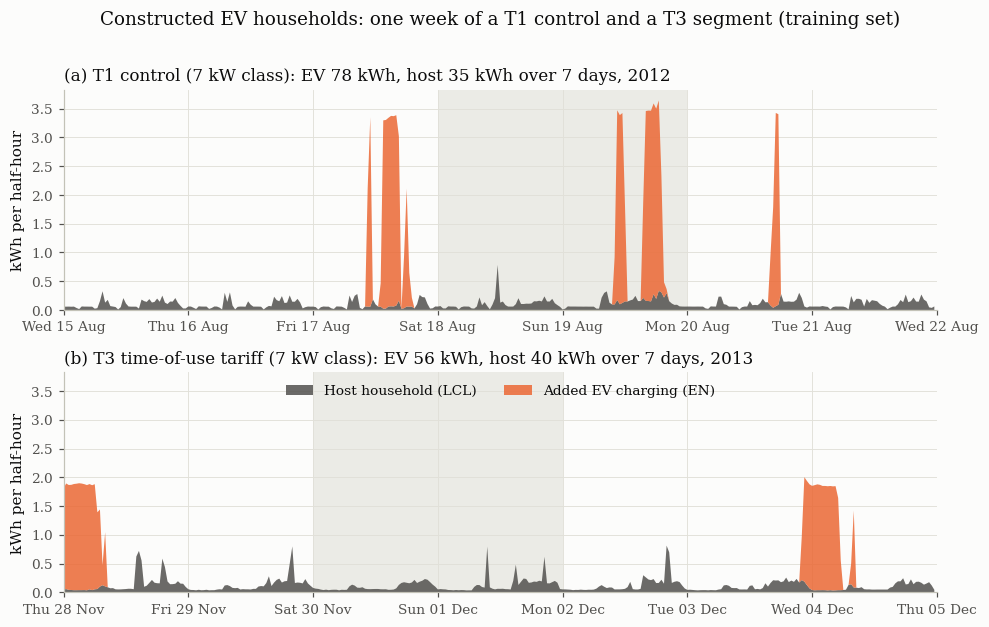

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharey=True)
for ax, (r, p), tag in zip(axes, picked.items(), "ab"):
    one = seg_load[seg_load.segment_id == p.segment_id].copy()
    one["week"] = (one.date - p.window_start).dt.days // 7
    wk_no = int(one.groupby("week").ev_kwh.sum().idxmax())
    start = p.window_start + pd.Timedelta(days=7 * wk_no)
    wk = one[one.week == wk_no]
    x = (wk.date - start).dt.days * 48 + wk.hh_index - 1
    for i in range(7):
        if (start + pd.Timedelta(days=i)).dayofweek >= 5:
            ax.axvspan(i * 48, (i + 1) * 48, color=GRID, alpha=0.6, linewidth=0)
    ax.stackplot(x, wk.host_kwh, wk.ev_kwh, colors=[CAT["grey"], CAT["orange"]], alpha=0.85,
                 labels=["Host household (LCL)", "Added EV charging (EN)"], linewidth=0)
    ax.set_xlim(0, 7 * 48)
    ax.set_xticks(range(0, 7 * 48 + 1, 48))
    ax.set_xticklabels([(start + pd.Timedelta(days=i)).strftime("%a %d %b") for i in range(8)])
    ax.set_ylabel("kWh per half-hour")
    ax.set_title(f"({tag}) {r} ({p.power_class}): EV {wk.ev_kwh.sum():.0f} kWh, "
                 f"host {wk.host_kwh.sum():.0f} kWh over 7 days, {start:%Y}", loc="left")
    if tag == "b":
        ax.legend(loc="upper center", frameon=False, ncol=2)
fig.suptitle("Constructed EV households: one week of a T1 control and a T3 segment (training set)",
             y=1.01)
fig.tight_layout()
savefig(fig, "EV_J1_example_ev_segments")
plt.show()

## 5. Table EV_J_T3 - Weekday and weekend consumption, EV segments against the rest

Per segment, over its complete days (at least 46 of 48 half-hours): mean daily kWh on weekdays
and on weekends, and the share of energy in the evening (16:00–22:00) and overnight
(22:00–07:00), in GMT. Each column summarises its segments: mean, or median where stated. EV
segments include the added charging; both splits are pooled.

In [9]:
per_seg = con.execute(f"""
    WITH d AS (
        SELECT segment_id, date, sum(kwh) AS kwh, isodow(date) >= 6 AS we
        FROM '{HH30}' GROUP BY 1, 2 HAVING count(*) >= {COMPLETE_DAY_SLOTS}),
    dd AS (
        SELECT segment_id, avg(kwh) FILTER (WHERE NOT we) AS weekday_kwh,
               avg(kwh) FILTER (WHERE we) AS weekend_kwh FROM d GROUP BY 1),
    sh AS (
        SELECT segment_id,
               sum(kwh) FILTER (WHERE hh_index BETWEEN {EVENING[0]} AND {EVENING[1]}) / sum(kwh) AS evening,
               sum(kwh) FILTER (WHERE hh_index IN {OVERNIGHT}) / sum(kwh) AS overnight
        FROM '{HH30}' GROUP BY 1)
    SELECT * FROM dd JOIN sh USING (segment_id)
""").df().merge(meta[["segment_id", "label", "regime", "ev_kwh_added"]], on="segment_id")
per_seg["ratio"] = per_seg.weekend_kwh / per_seg.weekday_kwh

groups = [(REGIME_SHORT[r], per_seg[per_seg.regime == r]) for r in REGIMES]
groups += [("All EV", per_seg[per_seg.label == 1]), ("No EV", per_seg[per_seg.label == 0])]
cols = {}
for name, g in groups:
    cols[name] = {
        "Segments": f"{len(g):,}",
        "Weekday kWh/day, mean": f"{g.weekday_kwh.mean():.1f}",
        "Weekend kWh/day, mean": f"{g.weekend_kwh.mean():.1f}",
        "Weekend/weekday ratio, median segment": f"{g.ratio.median():.2f}",
        "Evening share (16:00–22:00), mean": f"{100 * g.evening.mean():.1f}%",
        "Overnight share (22:00–07:00), mean": f"{100 * g.overnight.mean():.1f}%",
        "Added EV kWh/day, median": ("-" if name == "No EV"
                                     else f"{(g.ev_kwh_added / SEGMENT_DAYS).median():.1f}"),
    }
t_j5 = pd.DataFrame(cols)
t_j5.index.name = "EV_J_T3  Weekday and weekend consumption per 21-day segment"
savetable(t_j5, "EV_J_T3_weekday_weekend_consumption")
t_j5

saved -> tables/EV_J_T3_weekday_weekend_consumption.csv


,T1 control,T1,T2,T3,All EV,No EV
EV_J_T3 Weekday and weekend consumption per 21-day segment,,,,,,
Segments,28,459,473,418,"1,378","6,546"
"Weekday kWh/day, mean",13.1,16.8,15.6,17.8,16.6,9.9
"Weekend kWh/day, mean",12.5,16.6,15.3,17.4,16.3,10.4
"Weekend/weekday ratio, median segment",0.92,0.97,0.99,0.99,0.98,1.04
"Evening share (16:00–22:00), mean",40.7%,37.0%,37.9%,33.3%,36.3%,35.4%
"Overnight share (22:00–07:00), mean",29.4%,30.6%,30.2%,36.0%,32.1%,26.1%
"Added EV kWh/day, median",4.8,4.6,4.4,5.4,4.8,-


## 6. Figure EV_J2 - Mean half-hourly load, weekday and weekend

Mean kWh per half-hour over every reading of (a) the EV segments and (b) the segments without an
EV, both splits pooled, on weekdays and weekends. EV segments include the added charging. Both
panels share the y-axis.

saved -> figures/EV_J2_load_profiles_ev_segments.png


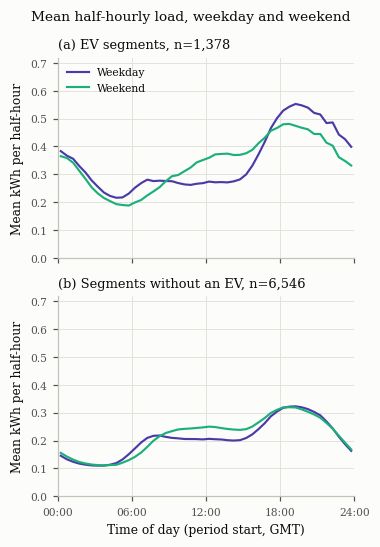

EV weekday: peak 0.553 kWh at slot 39, 16.6 kWh/day
EV weekend: peak 0.481 kWh at slot 38, 16.3 kWh/day
No EV weekday: peak 0.323 kWh at slot 39, 9.9 kWh/day
No EV weekend: peak 0.319 kWh at slot 38, 10.4 kWh/day


In [10]:
prof = con.execute(f"""
    SELECT label, isodow(date) >= 6 AS weekend, hh_index, avg(kwh) AS kwh
    FROM '{HH30}' GROUP BY 1, 2, 3 ORDER BY 1, 2, 3
""").df()

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.0), sharex=True, sharey=True)
    for ax, lab, tag, title, n in [(axes[0], 1, "a", "EV segments", len(pos)),
                                   (axes[1], 0, "b", "Segments without an EV", len(neg))]:
        for we, color, name in [(False, WEEKDAY_COLOR, "Weekday"), (True, WEEKEND_COLOR, "Weekend")]:
            p = prof[(prof.label == lab) & (prof.weekend == we)]
            ax.plot(p.hh_index - 0.5, p.kwh, color=color, linewidth=1.4, label=name)
        ax.set_title(f"({tag}) {title}, n={n:,}", loc="left")
        ax.set_ylabel("Mean kWh per half-hour")
    hhmm_axis(axes[1], step_hours=6)
    axes[1].set_xlim(0, 48)
    axes[1].set_xlabel("Time of day (period start, GMT)")
    axes[0].set_ylim(0, prof.kwh.max() * 1.3)
    axes[0].legend(frameon=False, loc="upper left")
    fig.suptitle("Mean half-hourly load, weekday and weekend", fontsize=9)
    fig.tight_layout()
    savefig(fig, "EV_J2_load_profiles_ev_segments")
    plt.show()

for lab, name in [(1, "EV"), (0, "No EV")]:
    for we in (False, True):
        p = prof[(prof.label == lab) & (prof.weekend == we)]
        print(f"{name} {'weekend' if we else 'weekday'}: peak {p.kwh.max():.3f} kWh at slot "
              f"{int(p.loc[p.kwh.idxmax(), 'hh_index'])}, {p.kwh.sum():.1f} kWh/day")

## 7. Start dates of positives and negatives

The share of segments starting in each month and on each weekday. Negatives are drawn the same way
positives are placed, so the two distributions should match. This is what the metadata audit
tests (ROC-AUC in Table EV_J_T2).

In [11]:
def mix(col, order, labels):
    t = (meta.assign(cls=np.where(meta.label == 1, "EV segments", "No EV"))
         .groupby(["cls", col]).size().unstack(0).reindex(order))
    t = (100 * t / t.sum()).round(1)
    t.index = labels
    return t


meta["start_m"] = meta.window_start.dt.month
meta["start_dow"] = meta.window_start.dt.dayofweek
months = mix("start_m", range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug",
                                        "Sep", "Oct", "Nov", "Dec"])
months.index.name = "Start month, % of segments"
weekdays = mix("start_dow", range(7), DAY_LABELS)
weekdays.index.name = "Start weekday, % of segments"
savetable(months, "EV_J_S_segment_start_months")
savetable(weekdays, "EV_J_S_segment_start_weekdays")
con.close()
display(months.T)
display(weekdays.T)

saved -> tables/EV_J_S_segment_start_months.csv
saved -> tables/EV_J_S_segment_start_weekdays.csv


"Start month, % of segments",Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
cls,,,,,,,,,,,,
EV segments,11.2,5.2,7.1,6.3,6.7,8.3,8.3,8.9,8.7,9.9,10.1,9.3
No EV,10.1,6.6,5.9,5.7,7.3,7.7,9.1,9.4,9.5,9.9,9.2,9.7


"Start weekday, % of segments",Mon,Tue,Wed,Thu,Fri,Sat,Sun
cls,,,,,,,
EV segments,13.1,14.4,13.2,16.3,13.9,14.4,14.7
No EV,13.3,13.9,13.4,15.9,13.9,14.5,15.0


## 8. Notes and limitations

- Each EV household places a 2017–18 fleet, with small batteries and many plug-in hybrids, on a
  2011–14 London home, so charging energy is lower than for today's EVs.
- Unmanaged charging is excluded, because it is mostly onboarding time before a charger joined a
  trial group. T1 control (28 segments) are used.
- The dataset is for detecting home charging, not EV ownership: windows with no charging are
  excluded (Table EV_J_T2).
- Charging isn't matched to the host's season, so a winter EV segment can sit in summer host load.
  This avoids tying T3, recorded only in autumn 2018, to autumn hosts.
- Up to four segments come from one charger, so they are correlated, and EV confidence intervals
  use a bootstrap over chargers.
- Charging keeps its local clock time on the host date, so in summer it appears an hour earlier on
  the GMT axis, as the host's own activity does.
- Test prevalence is fixed at 10%, so precision and F1 are restated at other prevalences from
  recall and the false-positive rate.